# SANDI: Marginalization via Gaussian Priors

Notebook 03 showed that fitting the full SANDI model (free d_in, d_ex) requires very high SNR because the diffusivities and structural parameters (r_soma, fractions) are partially degenerate. A practical solution is **Bayesian marginalization**: instead of fixing diffusivities to point values, we place **Gaussian priors** on them and let MCMC integrate over their uncertainty.

**Key ideas covered in this notebook:**
1. A `GaussianPriorFitter` class that extends `EmceeFitter` with per-parameter Gaussian penalties
2. How prior width controls the trade-off between regularization and data-driven estimation
3. Fitting with a **reduced acquisition** (b = 0, 1, 2, 3 ms/µm²) — only 4 shells — to show that marginalization enables stable inference even with limited data where the full free model is underdetermined

In [1]:
from pathlib import Path
import sys

def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/.")

repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

import numpy as np
import matplotlib.pyplot as plt

from dmri_models import Acquisition, EmceeFitter, GaussianNoise, LeastSquaresFitter, sandi
from dmri_models.acquisitions import sandi_full_acq
from dmri_models.fitting.mcmc import MCMCResult

rng = np.random.default_rng(42)

## GaussianPriorFitter

The standard `EmceeFitter` uses uniform priors within parameter bounds. We extend it with a `GaussianPriorFitter` that adds log-Gaussian penalty terms for any named parameters:

$$\log p(\theta) = \log p_\text{uniform}(\theta) + \sum_i \left[ -\frac{1}{2}\left(\frac{\theta_i - \mu_i}{\sigma_i}\right)^2 \right]$$

Gaussian priors on the diffusivities d_in and d_ex encode our belief that they are close to literature values, while allowing the data to update them. A prior width of σ = 0.3 µm²/ms means we are confident to within about ±0.6 µm²/ms at 2σ.

In [2]:
class GaussianPriorFitter(EmceeFitter):
    """EmceeFitter extended with optional Gaussian priors on named parameters.

    Parameters
    ----------
    gaussian_priors:
        Dict of {parameter_name: (mu, sigma)}.  A Gaussian penalty
        -0.5 * ((x - mu) / sigma)**2 is added to the log-posterior for each
        named parameter found in the parameter space.
    """

    def __init__(self, model, parameter_space, noise, *, gaussian_priors=None):
        super().__init__(model, parameter_space, noise)
        self.gaussian_priors = dict(gaussian_priors or {})

    def log_posterior(self, vector, acquisition, data):
        base = super().log_posterior(vector, acquisition, data)
        if not np.isfinite(base):
            return -np.inf
        parameters = self.parameter_space.unpack(vector)
        log_gaussian = sum(
            -0.5 * ((parameters[name] - mu) / sigma) ** 2
            for name, (mu, sigma) in self.gaussian_priors.items()
            if name in parameters
        )
        return base + log_gaussian

## Synthetic Data

We use the same acquisition and true parameters as notebook 03 (same random seed) so results are directly comparable. PGSE timing matches the SANDI.ipynb reference (δ = 13 ms, Δ = 22 ms), giving greater sensitivity to soma radius than the longer timings used in earlier versions.

After simulating 420 directional measurements (60 per shell × 7 shells) we average per shell to form 7 spherical mean values, each with noise reduced by √60 ≈ 7.7.

In [ ]:
# Acquisition and ground truth (same as notebook 03)
acquisition = sandi_full_acq()
SNR = 50
S0 = 1
sigma = S0 / SNR  

# Define SANDI model GT parameters
true_parameters = {
    "S0": S0, "r_soma": 7.0, "d_in": 2.0, "d_ex": 1.5,
    "d_sphere": 3.0, "soma_fraction": 0.22, "neurite_fraction": 0.50, "extra_fraction": 0.28,
}

# Simulate (d_sphere fixed, d_in/d_ex at true values for simulation)
sim_preset = sandi(d_sphere=true_parameters["d_sphere"],
                   d_in=true_parameters["d_in"], d_ex=true_parameters["d_ex"])
signal_sim = sim_preset.model.signal(acquisition, true_parameters)
signal_noisy = signal_sim + rng.normal(0.0, sigma, size=signal_sim.shape)

# Spherical mean over all 7 shells
b_vals = acquisition.b_values
b_shells_all = np.unique(np.round(b_vals, 4))

sm_signal_all, sm_b_all, n_dirs_all = [], [], []
for b in b_shells_all:
    mask = np.abs(b_vals - b) < 1e-4
    sm_signal_all.append(np.mean(signal_noisy[mask]))
    sm_b_all.append(b)
    n_dirs_all.append(mask.sum())

sm_signal_all = np.array(sm_signal_all)
sm_b_all = np.array(sm_b_all)
n_dirs_all = np.array(n_dirs_all)
sigma_sm_all = sigma / np.sqrt(n_dirs_all)   # Per-shell noise: same sigma everywhere

# Full spherical mean acquisition (7 shells)
acq_sm_full = Acquisition.from_pgse(sm_b_all, b_unit="ms/um^2",
    pulse_duration=acquisition.pulse_duration[0],
    diffusion_time=acquisition.diffusion_time[0],
    b_tensor_shape=acquisition.b_tensor_shape[0])

# Reduced spherical mean acquisition (b = 0, 1, 2, 3 ms/µm² only)
target_shells = {0.0, 1.0, 2.0, 3.0}
reduced_mask = np.array([round(float(b), 1) in target_shells for b in sm_b_all])
acq_sm_reduced = Acquisition.from_pgse(sm_b_all[reduced_mask], b_unit="ms/um^2",
    pulse_duration=acquisition.pulse_duration[0],
    diffusion_time=acquisition.diffusion_time[0],
    b_tensor_shape=acquisition.b_tensor_shape[0])

print(f"SNR per direction: {SNR}  |  sigma = {sigma:.4f}")
print(f"Full acquisition:    {acq_sm_full.n_measurements} shells: {sm_b_all}")
print(f"Reduced acquisition: {acq_sm_reduced.n_measurements} shells: {sm_b_all[reduced_mask]}")
print(f"sigma_sm (60 dirs):  {sigma_sm_all[1]:.6f}")

Full acquisition:    7 shells: [0.  0.5 1.  2.  3.  4.  6. ]
Reduced acquisition: 4 shells: [0. 1. 2. 3.]
sigma per direction: 0.0200  |  sigma_sm (60 dirs): 0.00258


## MCMC with Gaussian Priors — Full Acquisition (7 shells)

We run three fits to show the effect of prior width:
- **Tight priors**: d_in ~ N(2.0, 0.2), d_ex ~ N(1.5, 0.2)  — strongly regularized, low uncertainty in diffusivities
- **Moderate priors**: d_in ~ N(2.0, 0.5), d_ex ~ N(1.5, 0.5) — weakly informative, most common practical choice

r_soma and the volume fractions use the standard uniform prior throughout (they are the parameters of scientific interest). d_sphere is fixed at 3.0 µm²/ms in all fits.

In [ ]:
# SANDI preset: d_sphere fixed, d_in and d_ex free (Gaussian prior applied externally)
preset = sandi(
    vary_sphere_diffusivity=False, vary_neurite_diffusivity=True, vary_extra_diffusivity=True,
    d_sphere=true_parameters["d_sphere"],
    d_in=true_parameters["d_in"],   # Starting point for MCMC
    d_ex=true_parameters["d_ex"],
)

mcmc_kwargs = dict(n_steps=3000, burn_in=1000, thin=2, n_walkers=32, progress=False)

# --- Tight priors: sigma = 0.2 µm²/ms ---
# GaussianNoise accepts a per-shell vector: sigma_sm_all = sigma / sqrt(n_dirs_per_shell)
# This correctly weights each shell by its noise level, even if shell sizes differ.
fitter_tight = GaussianPriorFitter(preset.model, preset.parameters,
    GaussianNoise(sigma=sigma_sm_all),
    gaussian_priors={"d_in": (2.0, 0.2), "d_ex": (1.5, 0.2)})
result_tight = fitter_tight.sample(acq_sm_full, sm_signal_all, rng=rng, **mcmc_kwargs)

# --- Moderate priors: sigma = 0.5 µm²/ms ---
fitter_moderate = GaussianPriorFitter(preset.model, preset.parameters,
    GaussianNoise(sigma=sigma_sm_all),
    gaussian_priors={"d_in": (2.0, 0.5), "d_ex": (1.5, 0.5)})
result_moderate = fitter_moderate.sample(acq_sm_full, sm_signal_all, rng=rng, **mcmc_kwargs)

print("Full acquisition results (posterior mean ± SD):")
print(f"{'Parameter':<18} {'True':>8} {'Tight(0.2)':>14} {'Mod(0.5)':>14}")
print("-" * 58)
for p in ["r_soma", "d_in", "d_ex", "soma_fraction", "neurite_fraction"]:
    s_t = result_tight.physical_samples(flat=True)[p]
    s_m = result_moderate.physical_samples(flat=True)[p]
    tv = true_parameters[p]
    print(f"{p:<18} {tv:>8.3f} {np.mean(s_t):>7.3f}±{np.std(s_t):.3f} {np.mean(s_m):>7.3f}±{np.std(s_m):.3f}")

Full acquisition results (posterior mean ± SD):
Parameter              True     Tight(0.2)       Mod(0.5)
----------------------------------------------------------
r_soma                7.000   7.030±0.439   7.131±0.669
d_in                  2.000   2.029±0.210   2.055±0.508
d_ex                  1.500   1.564±0.124   1.539±0.209
soma_fraction         0.220   0.235±0.056   0.239±0.063
neurite_fraction      0.500   0.478±0.128   0.475±0.155


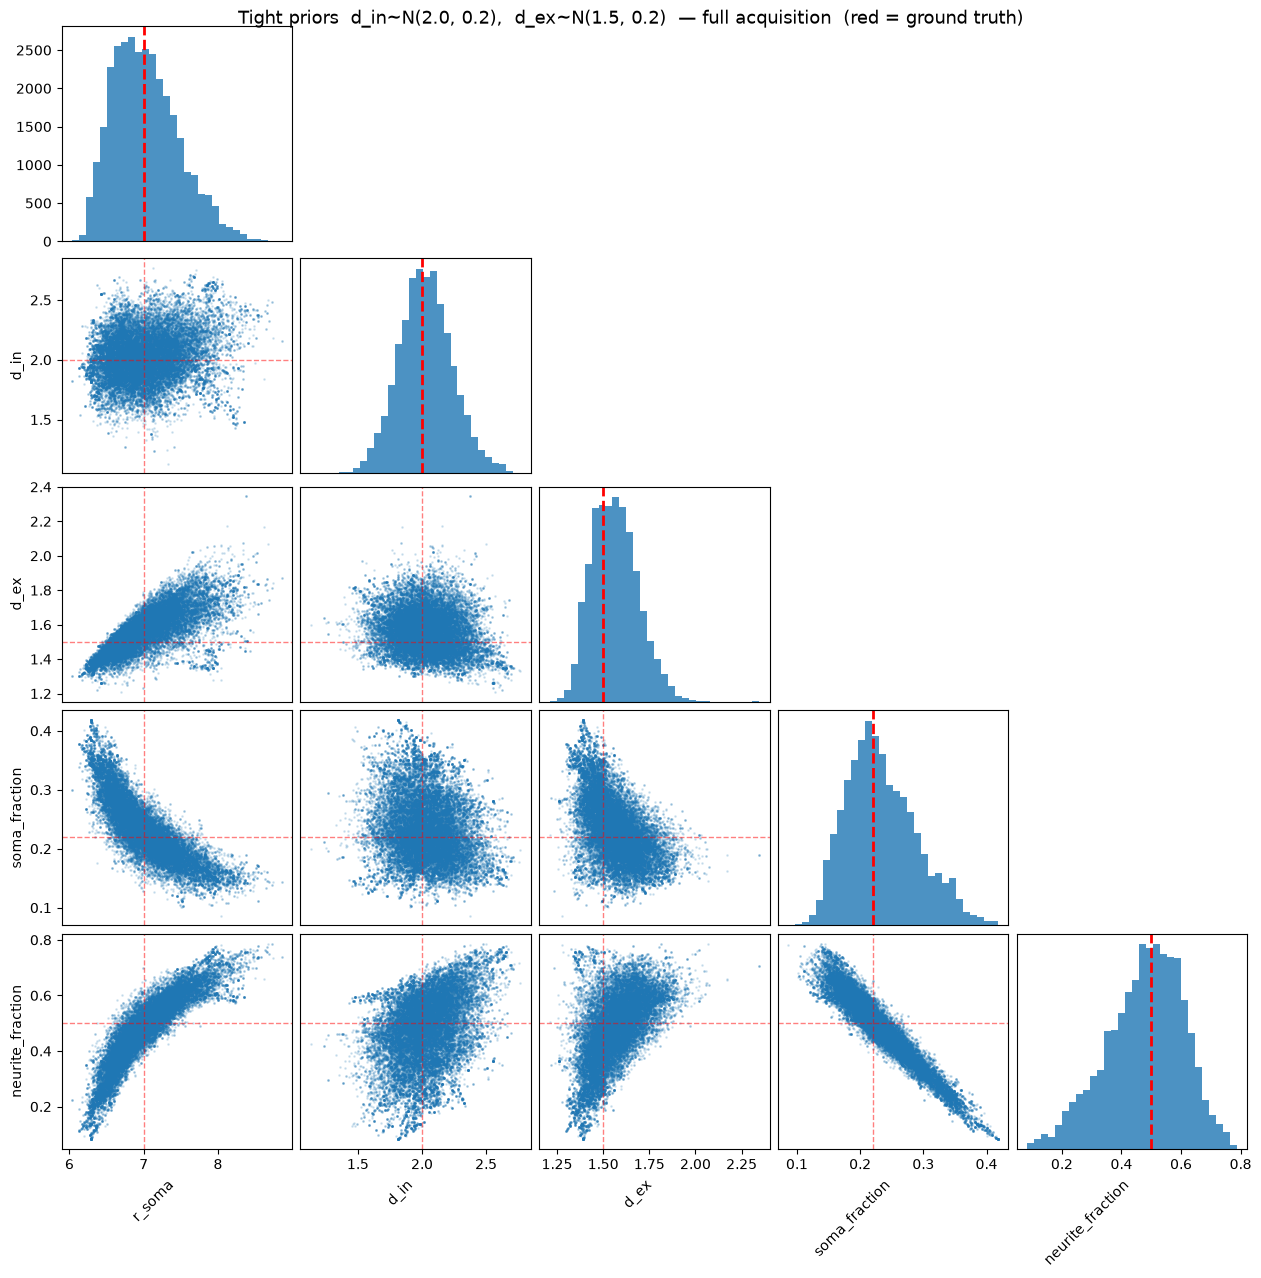

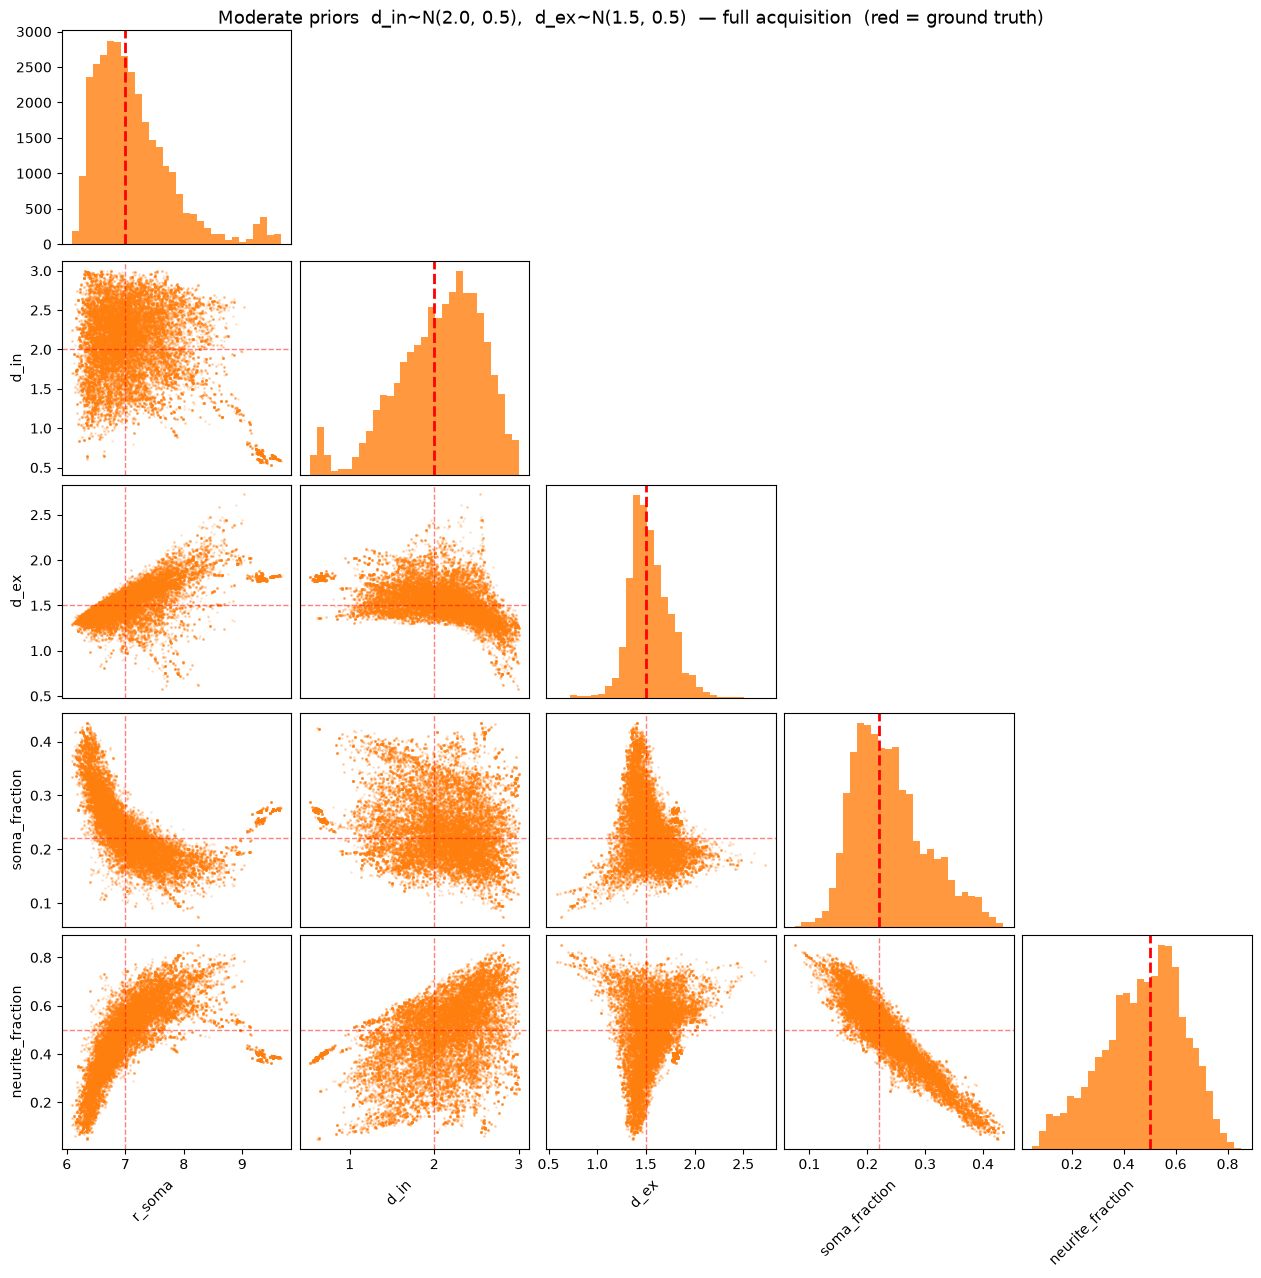

In [15]:
# Pair plots for tight and moderate priors (full acquisition)
plot_params = ["r_soma", "d_in", "d_ex", "soma_fraction", "neurite_fraction"]

def pair_plot(result, true_parameters, title, color="tab:blue"):
    s = result.physical_samples(flat=True)
    X = np.vstack([s[p] for p in plot_params]).T
    n = len(plot_params)
    fig, axes = plt.subplots(n, n, figsize=(2.5 * n, 2.5 * n), constrained_layout=True)
    for i in range(n):
        for j in range(n):
            ax = axes[i, j]
            if i == j:
                ax.hist(X[:, j], bins=30, color=color, alpha=0.8, edgecolor="none")
                ax.axvline(true_parameters[plot_params[j]], color="red", lw=2, ls="--")
            elif i > j:
                ax.scatter(X[:, j], X[:, i], s=1, alpha=0.15, color=color)
                ax.axvline(true_parameters[plot_params[j]], color="red", lw=1, alpha=0.5, ls="--")
                ax.axhline(true_parameters[plot_params[i]], color="red", lw=1, alpha=0.5, ls="--")
            else:
                ax.axis("off")
            if i == n - 1:
                ax.set_xlabel(plot_params[j], rotation=45, ha="right")
            else:
                ax.set_xticks([])
            if j == 0 and i > 0:
                ax.set_ylabel(plot_params[i])
            elif j != 0:
                ax.set_yticks([])
    fig.suptitle(title + "  (red = ground truth)", y=1.01, fontsize=13)
    plt.show()

pair_plot(result_tight,    true_parameters, "Tight priors  d_in~N(2.0, 0.2),  d_ex~N(1.5, 0.2)  — full acquisition")
pair_plot(result_moderate, true_parameters, "Moderate priors  d_in~N(2.0, 0.5),  d_ex~N(1.5, 0.5)  — full acquisition", color="tab:orange")

## Reduced Acquisition (b = 0, 1, 2, 4 ms/µm²)

With only 4 b-shells the soma sphere signal is nearly flat — the highest shell at b = 3 ms/µm² gives a signal difference of only ~0.07 between r = 5 µm and r = 7 µm, compared to the noise floor of σ_SM ≈ 0.00026. There is therefore limited sensitivity to r_soma and its posterior will be wide.

For the reduced acquisition we also place a **Gaussian prior on r_soma** to marginalise it out, leaving the volume fractions as the primary quantities of interest.

Prior choices:
- d_in ~ N(2.0, 0.3), d_ex ~ N(1.5, 0.3) — moderate diffusivity priors
- r_soma ~ N(7.0, 2.0) — broad prior covering ±6 µm at 3σ

> **Important**: the `GaussianNoise` sigma passed to the MCMC fitter must be the spherical-mean noise `sigma_sm_all[reduced_mask].mean()`, not the raw per-direction sigma. Passing the wrong sigma makes the likelihood too flat and causes the prior to dominate completely.

**IMPORTANT** this requires more MCMC samples and burnin!

**IMPORTANT** b=1,2,4 is much better than b=1,2,3. The b=4 shell does improve fraction fitting if you can get it

In [71]:
SNR = 100
S0 = 1
sigma = S0 / SNR  


# Simulate (d_sphere fixed, d_in/d_ex at true values for simulation)
sim_preset = sandi(d_sphere=true_parameters["d_sphere"],
                   d_in=true_parameters["d_in"], d_ex=true_parameters["d_ex"])
signal_sim = sim_preset.model.signal(acquisition, true_parameters)
signal_noisy = signal_sim + rng.normal(0.0, sigma, size=signal_sim.shape)

# Spherical mean over all 7 shells
b_vals = acquisition.b_values
b_shells_all = np.unique(np.round(b_vals, 4))

sm_signal_all, sm_b_all, n_dirs_all = [], [], []
for b in b_shells_all:
    mask = np.abs(b_vals - b) < 1e-4
    sm_signal_all.append(np.mean(signal_noisy[mask]))
    sm_b_all.append(b)
    n_dirs_all.append(mask.sum())

sm_signal_all = np.array(sm_signal_all)
sm_b_all = np.array(sm_b_all)
n_dirs_all = np.array(n_dirs_all)
sigma_sm_all = sigma / np.sqrt(n_dirs_all)

# Full spherical mean acquisition (7 shells)
acq_sm_full = Acquisition.from_pgse(sm_b_all, b_unit="ms/um^2",
    pulse_duration=acquisition.pulse_duration[0], diffusion_time=acquisition.diffusion_time[0], b_tensor_shape=acquisition.b_tensor_shape[0])

# Reduced spherical mean acquisition (b = 0, 0.5, 1, 2, 3 ms/µm² only)
target_shells = {0.0, 1.0, 2.0, 4.0}
reduced_mask = np.array([round(float(b), 1) in target_shells for b in sm_b_all])
acq_sm_reduced = Acquisition.from_pgse(sm_b_all[reduced_mask], b_unit="ms/um^2",
    pulse_duration=acquisition.pulse_duration[0], diffusion_time=acquisition.diffusion_time[0], b_tensor_shape=acquisition.b_tensor_shape[0])

print(f"Full acquisition:    {acq_sm_full.n_measurements} shells: {sm_b_all}")
print(f"Reduced acquisition: {acq_sm_reduced.n_measurements} shells: {sm_b_all[reduced_mask]}")
print(f"sigma per direction: {sigma:.4f}  |  sigma_sm (60 dirs): {sigma_sm_all[1]:.5f}")

Full acquisition:    7 shells: [0.  0.5 1.  2.  3.  4.  6. ]
Reduced acquisition: 4 shells: [0. 1. 2. 4.]
sigma per direction: 0.0100  |  sigma_sm (60 dirs): 0.00129


In [72]:

# Reduced acquisition: marginalise over d_in, d_ex AND r_soma
# r_soma prior: N(7.0, 2.0) — broad (covers ±6 µm at 3σ), acknowledges we don't know the true radius
# d_in, d_ex: moderate priors matching the full-acquisition moderate condition
priors_reduced = {
    "d_in":   (2.0, 0.3),
    "d_ex":   (1.5, 0.3),
    "r_soma": (7.0, 0.3),
}

mcmc_kwargs = dict(n_steps=10000, burn_in=5000, thin=2, n_walkers=32, progress=False)

result_reduced = GaussianPriorFitter(
    preset.model, preset.parameters,
    GaussianNoise(sigma=sigma_sm_all[reduced_mask]),
    gaussian_priors=priors_reduced,
).sample(acq_sm_reduced, sm_signal_all[reduced_mask], rng=rng, **mcmc_kwargs)

print("Reduced acquisition — Gaussian priors on d_in, d_ex AND r_soma:")
print(f"{'Parameter':<18} {'True':>8} {'Mean':>10} {'SD':>10} {'95% CI':<20}")
print("-" * 66)
for p in ["r_soma", "d_in", "d_ex", "soma_fraction", "neurite_fraction"]:
    s = result_reduced.physical_samples(flat=True)[p]
    lo, hi = np.quantile(s, [0.025, 0.975])
    print(f"{p:<18} {true_parameters[p]:>8.3f} {np.mean(s):>10.3f} {np.std(s):>10.3f} ({lo:.3f}, {hi:.3f})")

Reduced acquisition — Gaussian priors on d_in, d_ex AND r_soma:
Parameter              True       Mean         SD 95% CI              
------------------------------------------------------------------
r_soma                7.000      7.048      0.426 (6.462, 8.834)
d_in                  2.000      2.088      0.331 (1.483, 2.943)
d_ex                  1.500      1.475      0.226 (0.410, 1.735)
soma_fraction         0.220      0.250      0.082 (0.024, 0.440)
neurite_fraction      0.500      0.454      0.148 (0.076, 0.754)


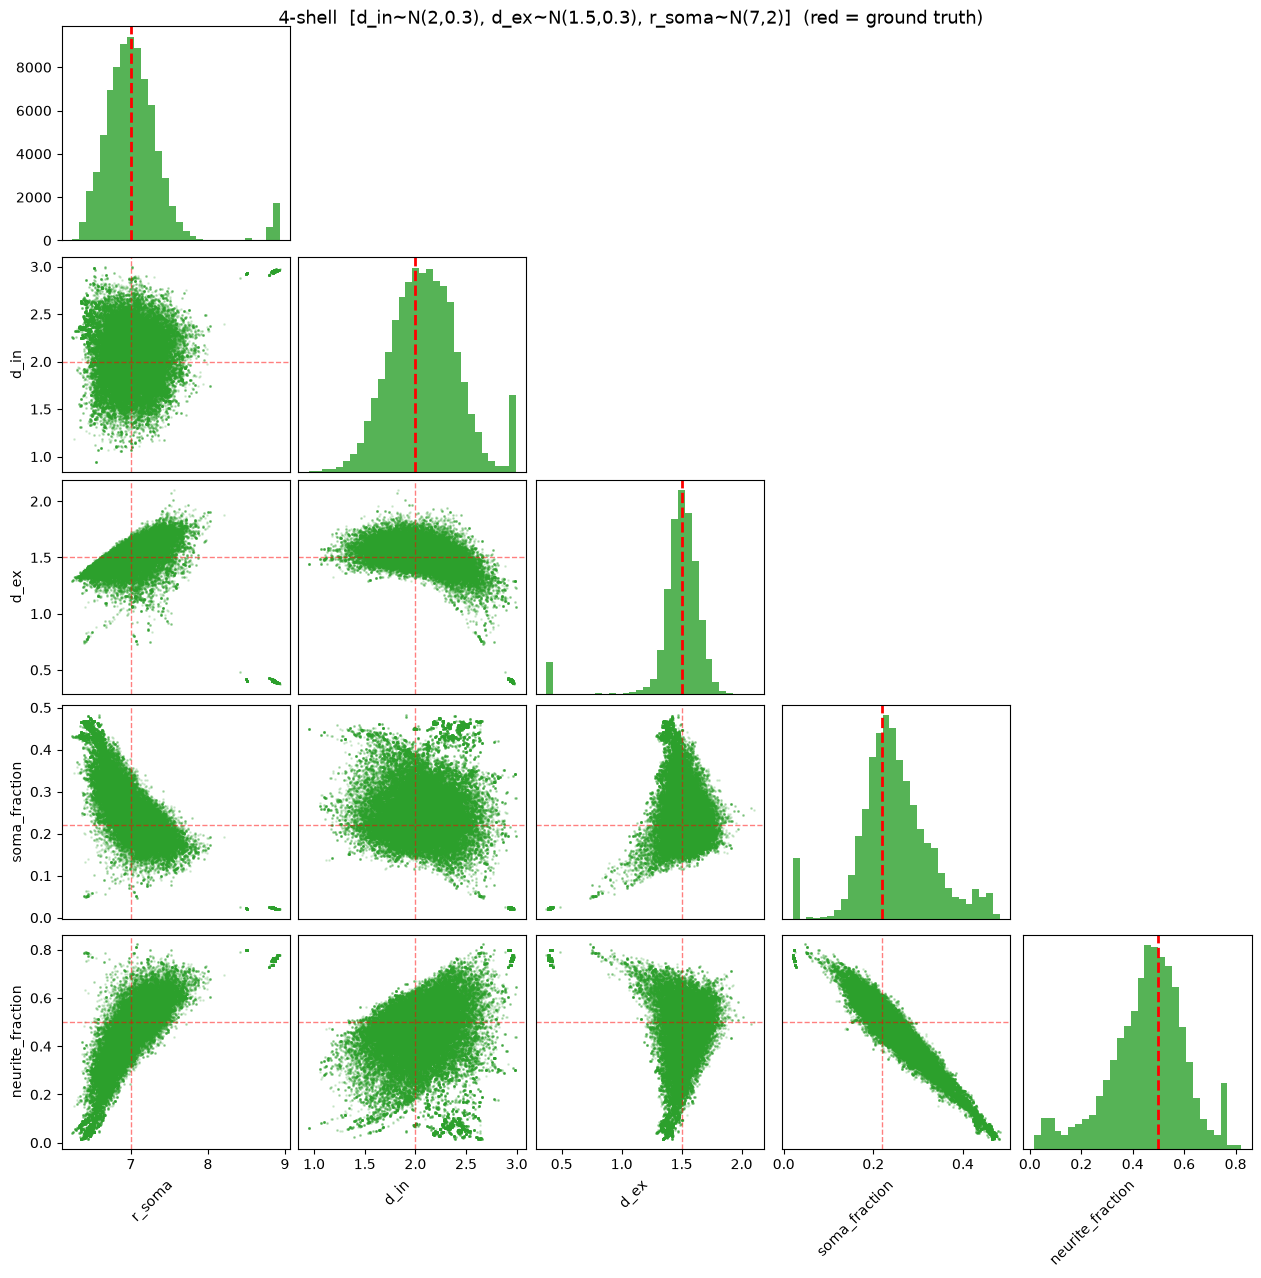

In [73]:
pair_plot(result_reduced, true_parameters,
    "4-shell  [d_in~N(2,0.3), d_ex~N(1.5,0.3), r_soma~N(7,2)]",
    color="tab:green")

## Comparison: Full vs Reduced Acquisition

The plot below overlays the posterior marginals for r_soma and the two fractions across all four conditions (2 prior widths × 2 acquisition sizes), making it easy to see how acquisition length and prior width each affect uncertainty.

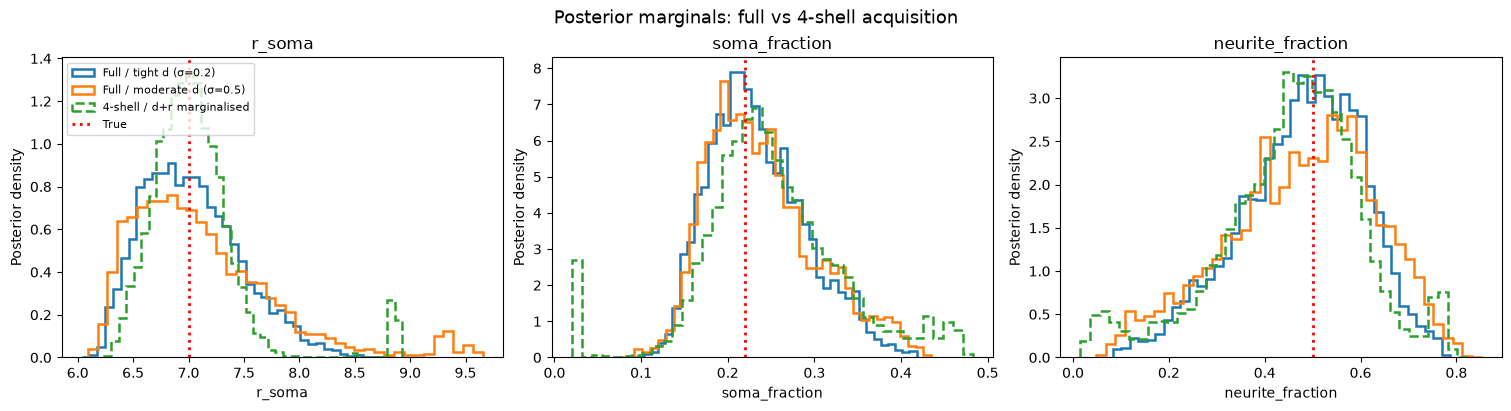

In [74]:
compare_params = ["r_soma", "soma_fraction", "neurite_fraction"]
conditions = [
    (result_tight,    "Full / tight d (σ=0.2)",      "tab:blue",   "-"),
    (result_moderate, "Full / moderate d (σ=0.5)",   "tab:orange",  "-"),
    (result_reduced,  "4-shell / d+r marginalised",  "tab:green",  "--"),
]

fig, axes = plt.subplots(1, len(compare_params), figsize=(5 * len(compare_params), 4), constrained_layout=True)
for ax, param in zip(axes, compare_params):
    for result, label, color, ls in conditions:
        vals = result.physical_samples(flat=True)[param]
        ax.hist(vals, bins=40, density=True, histtype="step",
                linewidth=1.8, color=color, linestyle=ls, label=label)
    ax.axvline(true_parameters[param], color="red", lw=2, ls=":", label="True")
    ax.set_xlabel(param)
    ax.set_ylabel("Posterior density")
    ax.set_title(param)

axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle("Posterior marginals: full vs 4-shell acquisition", fontsize=13)
plt.show()

## Summary

**Marginalization via Gaussian priors** provides a principled middle ground between fixing parameters to point values (which ignores uncertainty) and letting them be entirely free (which requires very high SNR or many b-shells):

| Approach | d_in / d_ex | r_soma | Acquisition needed | Fractions identifiable? |
|---|---|---|---|---|
| Fixed diffusivities | Point value | Free | Any | Yes, if values correct |
| Free, no prior | Uniform in bounds | Free | Full (7+ shells), high SNR | Moderate |
| **Gaussian prior on d** | **Regularized** | **Free** | **Full (7 shells)** | **Yes** |
| **Gaussian prior on d + r** | **Regularized** | **Regularized** | **4 shells only** | **Yes** |

**Key observations:**
- On the **full acquisition**, tight diffusivity priors (σ = 0.2 µm²/ms) give narrow posteriors for all parameters; moderate priors (σ = 0.5) allow the data to push diffusivities away from the prior centre if warranted
- On the **4-shell acquisition**, the sphere signal provides almost no contrast for r_soma at b ≤ 3 ms/µm². Adding a Gaussian prior on r_soma marginalises it out; the fractions are then well-recovered because they are well-constrained by the signal decay shape even at low b
- r_soma posterior on the 4-shell data is prior-dominated (wide, centred near the prior mean) — this is the honest Bayesian outcome when data are uninformative about a parameter

**Practical advice**: When designing a clinical SANDI protocol under scan-time constraints, using Gaussian priors on diffusivities (and r_soma if only low b-values are accessible) allows estimation of soma and neurite fractions from a shorter acquisition. The prior widths should reflect the expected biological variability across the population being studied.


---------------------

## Soma Fraction Recovery Sweep

To demonstrate that the Gaussian-prior approach can reliably track differences in soma density, we repeat the reduced-acquisition fit across a range of true soma fractions (f_soma = 0.05 → 0.5), with the extra-axonal fraction fixed at 0.15 and neurite fraction filling the remainder.

For each f_soma value we run **5 independent noise realisations** (different random seeds), then plot:
- **Error bars**: standard deviation of the posterior mean *across the 5 runs* — noise sensitivity / scan-to-scan variability
- **Shaded band**: mean posterior width (average posterior SD within each run) — intrinsic parameter uncertainty

### Why f_soma = 0 cannot be estimated

The `ParameterSpace` uses a **Dirichlet(1) prior** on simplex fractions, implemented via additive log-ratio (ALR) coordinates. This prior contributes $\sum_i \log(f_i)$ to the log-posterior, which diverges to $-\infty$ as any fraction approaches zero — a hard log-barrier at the boundary. Reaching exactly zero would require the corresponding ALR coordinate to be $-\infty$, which no finite sampler can achieve.

This is correct Bayesian behaviour: a Dirichlet(1) prior assigns zero probability mass to degenerate (zero-component) simplices. In practice this means the posterior for soma fraction will always have support above zero, even when the true value is zero. The **effective detection floor** is roughly where the log-prior penalty $|\log(f_\text{soma})|$ becomes comparable to the likelihood curvature — typically a few percent for these acquisition parameters.

f_soma=0.0  est=0.105±0.040  post_sd=0.103
f_soma=0.1  est=0.135±0.030  post_sd=0.086
f_soma=0.2  est=0.197±0.027  post_sd=0.092
f_soma=0.3  est=0.248±0.039  post_sd=0.082
f_soma=0.4  est=0.372±0.077  post_sd=0.096
f_soma=0.5  est=0.459±0.051  post_sd=0.111


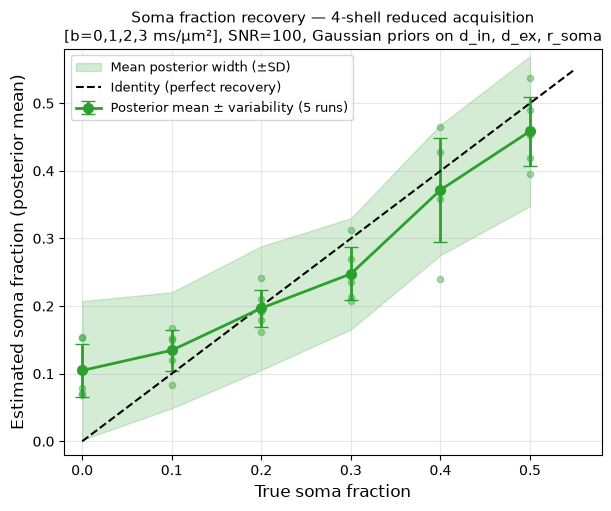

In [ ]:
# --- Sweep parameters (self-contained: doesn't depend on earlier cell state) ---
# Start from 0.05 rather than 0.0: the Dirichlet(1) prior creates a log-barrier
# at the simplex boundary (log(f_soma) -> -inf as f_soma -> 0), so the sampler
# cannot reach exactly zero.
F_SOMA_RANGE = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5]
F_EXTRA_FIXED = 0.15   # extra-axonal fraction held constant
N_RUNS = 5             # independent noise realizations per f_soma

SWEEP_SNR = 100
sweep_sigma = 1.0 / SWEEP_SNR
sweep_sigma_sm = sweep_sigma / np.sqrt(n_dirs_all)   # per-shell; same for all shells here

# Reduced acquisition: b = 0, 1, 2, 4 ms/µm²
sweep_target = {0.0, 1.0, 2.0, 4.0}
sweep_mask = np.array([round(float(b), 1) in sweep_target for b in sm_b_all])
acq_sweep = Acquisition.from_pgse(
    sm_b_all[sweep_mask], b_unit="ms/um^2",
    pulse_duration=acquisition.pulse_duration[0],
    diffusion_time=acquisition.diffusion_time[0],
    b_tensor_shape=acquisition.b_tensor_shape[0],
)
noise_sweep = GaussianNoise(sigma=sweep_sigma_sm[sweep_mask])

priors_sweep = {"d_in": (2.0, 0.3), "d_ex": (1.5, 0.3), "r_soma": (7.0, 2.0)}
mcmc_sweep = dict(n_steps=5000, burn_in=1000, thin=2, n_walkers=24, progress=False)

rng_sweep = np.random.default_rng(77)

# --- Run sweep ---
posterior_means = np.empty((len(F_SOMA_RANGE), N_RUNS))   # posterior mean per run
posterior_sds   = np.empty((len(F_SOMA_RANGE), N_RUNS))   # posterior SD per run

for i, f_soma in enumerate(F_SOMA_RANGE):
    f_neur = 1.0 - f_soma - F_EXTRA_FIXED
    sweep_true = {**true_parameters,
                  "soma_fraction": f_soma,
                  "neurite_fraction": f_neur,
                  "extra_fraction": F_EXTRA_FIXED}

    for run in range(N_RUNS):
        # New noise realisation
        sig_clean = preset.model.signal(acquisition, sweep_true)
        sig_noisy = sig_clean + rng_sweep.normal(0.0, sweep_sigma, size=sig_clean.shape)

        # Spherical mean for this realisation
        sm_run = np.array([
            np.mean(sig_noisy[np.abs(b_vals - b) < 1e-4]) for b in sm_b_all
        ])

        result_run = GaussianPriorFitter(
            preset.model, preset.parameters,
            noise_sweep,
            gaussian_priors=priors_sweep,
        ).sample(acq_sweep, sm_run[sweep_mask], rng=rng_sweep, **mcmc_sweep)

        s_run = result_run.physical_samples(flat=True)["soma_fraction"]
        posterior_means[i, run] = float(np.mean(s_run))
        posterior_sds[i, run]   = float(np.std(s_run))

    print(f"f_soma={f_soma:.2f}  est={posterior_means[i].mean():.3f}±{posterior_means[i].std():.3f}  "
          f"post_sd={posterior_sds[i].mean():.3f}")

# --- Summary statistics ---
f_true = np.array(F_SOMA_RANGE)
est_mean = posterior_means.mean(axis=1)   # mean posterior mean across runs
est_std  = posterior_means.std(axis=1)    # variability across noise realizations
mean_post_sd = posterior_sds.mean(axis=1) # average within-run posterior width

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)

ax.fill_between(f_true, est_mean - mean_post_sd, est_mean + mean_post_sd,
                alpha=0.2, color="tab:green", label="Mean posterior width (±SD)")
ax.errorbar(f_true, est_mean, yerr=est_std, fmt="o-", capsize=5,
            color="tab:green", linewidth=2, markersize=7,
            label=f"Posterior mean ± variability ({N_RUNS} runs)")
for run in range(N_RUNS):
    ax.scatter(f_true, posterior_means[:, run], s=20, alpha=0.4, color="tab:green")

ax.plot([0, 0.55], [0, 0.55], "k--", linewidth=1.5, label="Identity (perfect recovery)")
ax.axvline(0.05, color="grey", ls=":", lw=1.2, alpha=0.8, label="Approx. detection floor (~0.05)")
ax.set_xlabel("True soma fraction", fontsize=12)
ax.set_ylabel("Estimated soma fraction (posterior mean)", fontsize=12)
ax.set_title(f"Soma fraction recovery — 4-shell reduced acquisition\n"
             f"[b=0,1,2,4 ms/µm²], SNR={SWEEP_SNR}, Gaussian priors on d_in, d_ex, r_soma",
             fontsize=11)
ax.legend(fontsize=9)
ax.set_xlim(-0.02, 0.58)
ax.set_ylim(-0.02, 0.58)
ax.grid(alpha=0.3)
plt.show()